In [426]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier


In [427]:
pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


find r2 score without feature selection and time


In [428]:
import kagglehub
import os
# Download latest version
path = kagglehub.dataset_download("rajyellow46/wine-quality")
path=os.path.join(path, "winequalityN.csv")
df=pd.read_csv(path)

In [429]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   str    
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [430]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6487.000000,6489.000000,6494.000000,6495.000000,6495.000000,6497.000000,6497.000000,6497.000000,6488.000000,6493.000000,6497.000000,6497.000000
mean,7.216579,0.339691,0.318722,5.444326,0.056042,30.525319,115.744574,0.994697,3.218395,0.531215,10.491801,5.818378
std,1.296750,0.164649,0.145265,4.758125,0.035036,17.749400,56.521855,0.002999,0.160748,0.148814,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [431]:
df["type"]=df["type"].map({"red":0, "white":1})

In [432]:
df=df.dropna()

In [433]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 1168


In [434]:
df=df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape after removing duplicates: (5295, 13)
Remaining duplicates: 0


In [435]:
df["quality"].value_counts()

quality
6    2311
5    1745
7     852
4     204
8     148
3      30
9       5
Name: count, dtype: int64

C:\Users\dell\AppData\Local\Temp\ipykernel_11160\3027455637.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x=df["quality"],palette="spring")


<Axes: xlabel='quality', ylabel='count'>

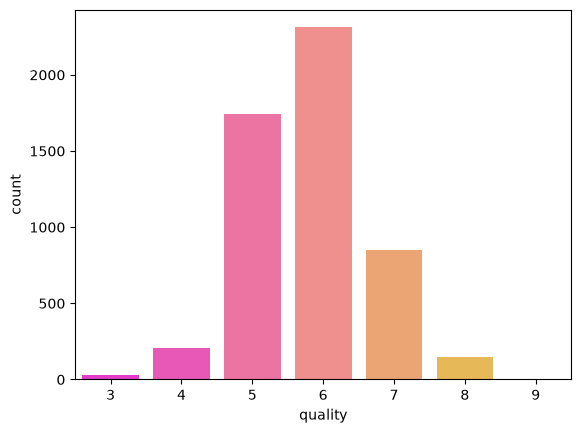

In [436]:
sns.countplot(data=df,x=df["quality"],palette="spring")

C:\Users\dell\AppData\Local\Temp\ipykernel_11160\1784074077.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x=df["quality"],palette="spring",order=["bad","low","medium","good","high"])


<Axes: xlabel='quality', ylabel='count'>

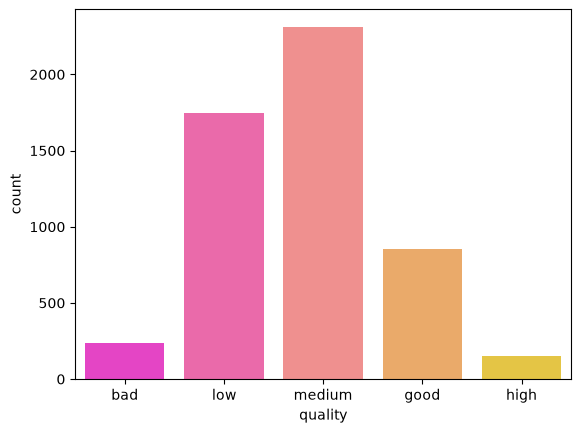

In [437]:
def quality_group(q):
    if q <= 4:
        return "bad"
    elif q <= 5:
        return "low"
    elif q<=6:
        return "medium"
    elif q<=7:
        return "good"
    else:
        return "high"
df["quality"]=df["quality"].apply(quality_group)
sns.countplot(data=df,x=df["quality"],palette="spring",order=["bad","low","medium","good","high"])

In [438]:
X_train, X_test, y_train, y_test = train_test_split(df.drop('quality', axis=1), df['quality'], test_size=0.2, random_state=42)

In [439]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 4236 entries, 1209 to 860
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  4236 non-null   int64  
 1   fixed acidity         4236 non-null   float64
 2   volatile acidity      4236 non-null   float64
 3   citric acid           4236 non-null   float64
 4   residual sugar        4236 non-null   float64
 5   chlorides             4236 non-null   float64
 6   free sulfur dioxide   4236 non-null   float64
 7   total sulfur dioxide  4236 non-null   float64
 8   density               4236 non-null   float64
 9   pH                    4236 non-null   float64
 10  sulphates             4236 non-null   float64
 11  alcohol               4236 non-null   float64
dtypes: float64(11), int64(1)
memory usage: 430.2 KB


In [440]:
from sklearn.metrics import accuracy_score, classification_report

model = Pipeline([
    ("scaling", StandardScaler()),
    ("pred", LogisticRegression(max_iter=500, random_state=42))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy: 0.5118
              precision    recall  f1-score   support

         bad       0.43      0.05      0.09        62
        good       0.47      0.25      0.33       166
        high       0.00      0.00      0.00        39
         low       0.58      0.59      0.59       362
      medium       0.48      0.66      0.55       430

    accuracy                           0.51      1059
   macro avg       0.39      0.31      0.31      1059
weighted avg       0.49      0.51      0.48      1059



In [441]:
# Feature Selection
#1.no dublicate columns
#2.no constant columns

In [442]:
columns_to_drop = df.drop(['type','quality'], axis=1).columns
result=[]
for i, col in enumerate(columns_to_drop):
    result.append([col, df[col].quantile(0.99)])
result

[['fixed acidity', np.float64(12.0)],
 ['volatile acidity', np.float64(0.890300000000002)],
 ['citric acid', np.float64(0.74)],
 ['residual sugar', np.float64(18.15)],
 ['chlorides', np.float64(0.2000600000000004)],
 ['free sulfur dioxide', np.float64(76.0)],
 ['total sulfur dioxide', np.float64(240.0)],
 ['density', np.float64(1.0005124)],
 ['pH', np.float64(3.65)],
 ['sulphates', np.float64(1.02)],
 ['alcohol', np.float64(13.4)]]

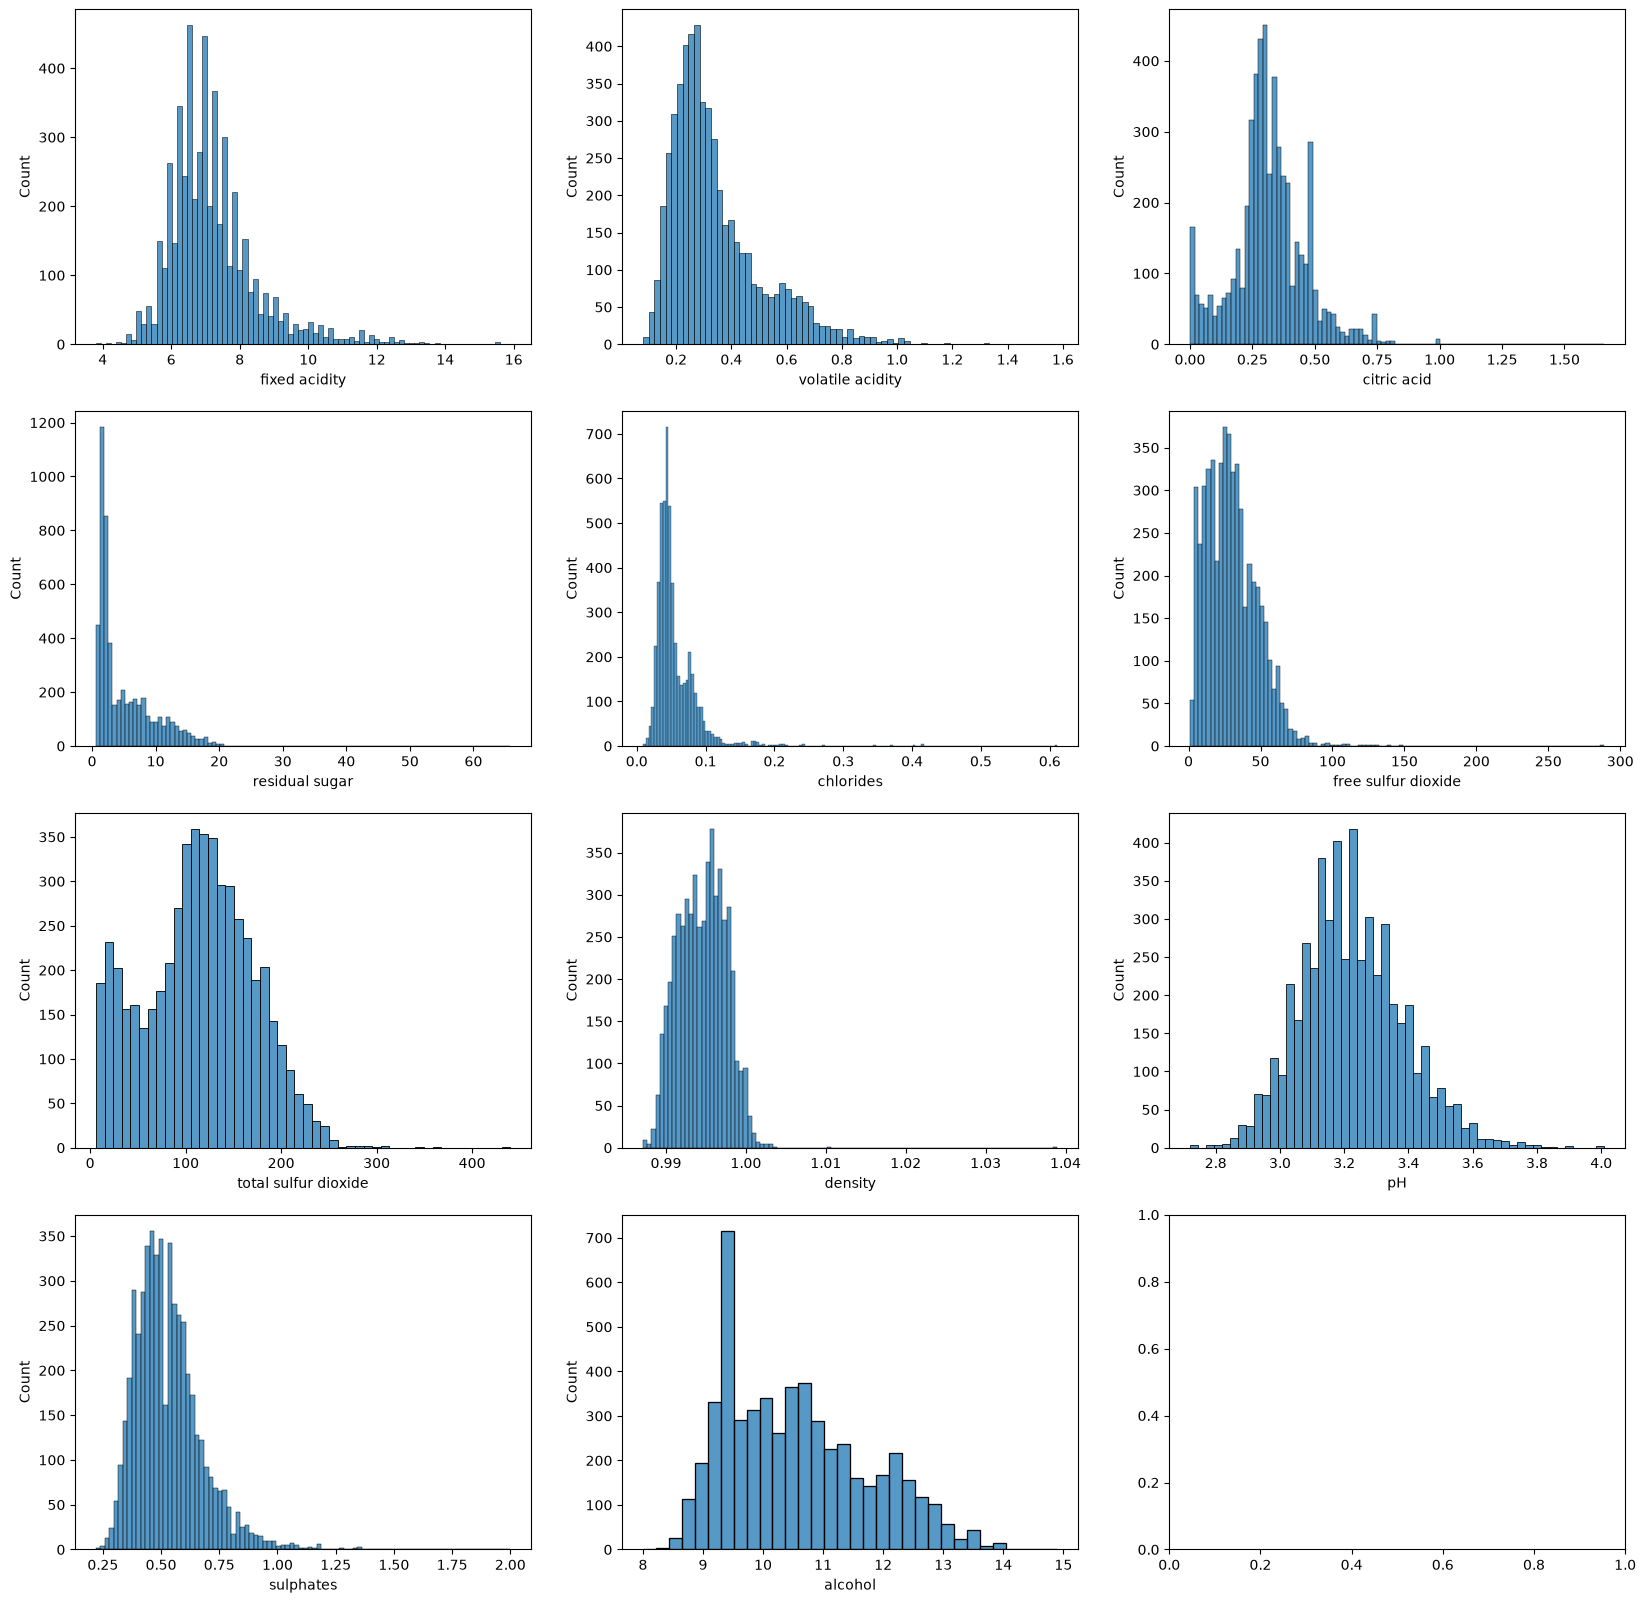

In [443]:
columns_to_drop = df.drop(['type','quality'], axis=1).columns
f,axis=plt.subplots(4, 3, figsize=(20,20))
for i, col in enumerate(columns_to_drop):
    sns.histplot(data=df, x=col, ax=axis[i//3, i%3])

In [444]:
#remove outlier
df = df[df["alcohol"]<=14.2]
df = df[df["free sulfur dioxide"]<=150]
df = df[df["chlorides"]<=0.20]
df = df[df["volatile acidity"]<=1.3]
df = df[df["pH"]<=3.8]
df = df[df["density"]<=1.005]
df = df[df["fixed acidity"]<=14]
df = df[df["citric acid"]<=1]
df = df[df["residual sugar"]<=22]
df = df[df["total sulfur dioxide"]<=300]
df = df[df["sulphates"]<=1.4]


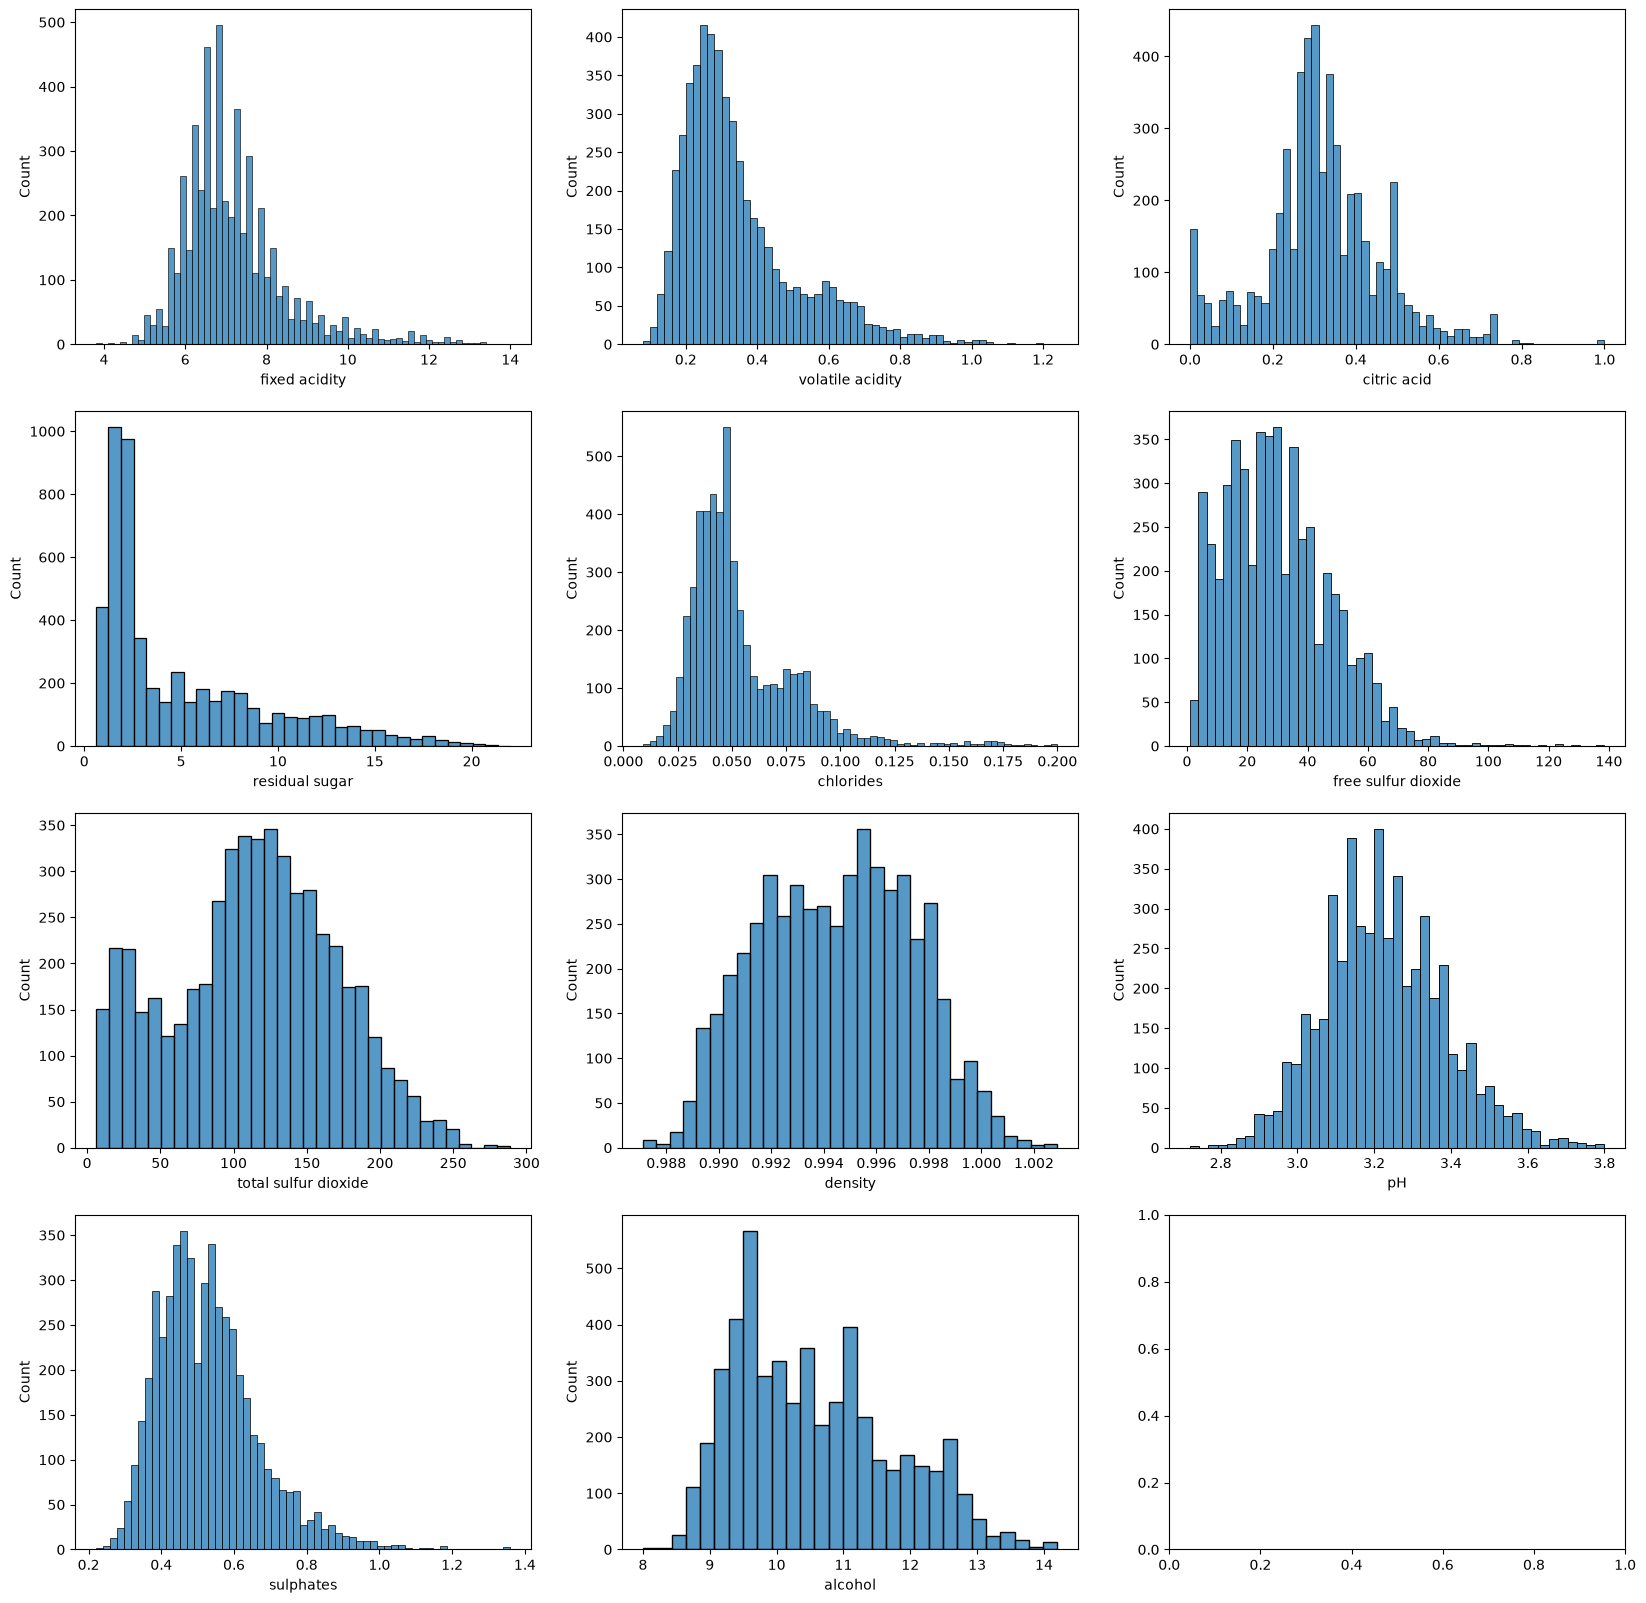

In [445]:
columns_to_drop = df.drop(['type','quality'], axis=1).columns
f,axis=plt.subplots(4, 3, figsize=(20,20))
for i, col in enumerate(columns_to_drop):
    sns.histplot(data=df, x=col, ax=axis[i//3, i%3])

In [446]:
X_train_, X_test_, y_train_, y_test_ = train_test_split(df.drop('quality', axis=1), df['quality'], test_size=0.2, random_state=42)

In [447]:
model = Pipeline([
    ("scaling", StandardScaler()),
    ("pred", LogisticRegression(max_iter=500, random_state=42))
])

model.fit(X_train_, y_train_)
y_pred_= model.predict(X_test_)

print("Accuracy:", round(accuracy_score(y_test_, y_pred_), 4))
print(classification_report(y_test_, y_pred_, zero_division=0))

Accuracy: 0.5576
              precision    recall  f1-score   support

         bad       0.71      0.11      0.20        44
        good       0.59      0.30      0.40       193
        high       0.00      0.00      0.00        27
         low       0.62      0.60      0.61       349
      medium       0.51      0.72      0.60       429

    accuracy                           0.56      1042
   macro avg       0.49      0.35      0.36      1042
weighted avg       0.56      0.56      0.53      1042



In [448]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=400,
    random_state=42,
    class_weight="balanced_subsample")
rf.fit(X_train_, y_train_)

y_pred_rf = rf.predict(X_test_)
accuracy=accuracy_score(y_test_,y_pred_rf)
accuracy

0.5796545105566219

In [449]:
gbr = GradientBoostingClassifier(random_state=42)
gbr.fit(X_train_, y_train_)
y_pred_gbr = gbr.predict(X_test_)
accuracy=accuracy_score(y_test_,y_pred_gbr)
accuracy

0.5585412667946257

without removing outlier:

model:  	accuracy| 	precision (macro)| 	recall (macro)| 	f1 (macro)

logistic regression:	0.511804, 0.391422, 0.310227, 0.311024

random forest:	0.559018, 0.552385, 0.349705, 0.362514

gradient boosting:	0.551464, 0.437267, 0.349920, 0.360641



In [450]:
#ro=remove outlier
results = pd.DataFrame({
    "model": ["logistic regression","logistic regression ro" ,"random forest ro", "gradient boosting ro"],
    "accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test_, y_pred_),
        accuracy_score(y_test_, y_pred_rf),
        accuracy_score(y_test_, y_pred_gbr)
    ],
    "precision (macro)": [
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        precision_score(y_test_, y_pred_, average="macro", zero_division=0),
        precision_score(y_test_, y_pred_rf, average="macro", zero_division=0),
        precision_score(y_test_, y_pred_gbr, average="macro", zero_division=0)
    ],
    "recall (macro)": [
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test_, y_pred_, average="macro", zero_division=0),
        recall_score(y_test_, y_pred_rf, average="macro", zero_division=0),
        recall_score(y_test_, y_pred_gbr, average="macro", zero_division=0)
    ],
    "f1 (macro)": [
        f1_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test_, y_pred_, average="macro", zero_division=0),
        f1_score(y_test_, y_pred_rf, average="macro", zero_division=0),
        f1_score(y_test_, y_pred_gbr, average="macro", zero_division=0)
    ]
})
results


,model,accuracy,precision (macro),recall (macro),f1 (macro)
0,logistic regression,0.511804,0.391422,0.310227,0.311024
1,logistic regression ro,0.557582,0.487696,0.346764,0.361023
2,random forest ro,0.579655,0.513783,0.357499,0.370320
3,gradient boosting ro,0.558541,0.436669,0.359125,0.374438


we cant use variencethreshold beacause on diffrent scaling

In [451]:
df.drop("quality",axis=1).corr(method="pearson")

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
type,1.000000,-0.490844,-0.648015,0.198999,0.331614,-0.621946,0.472255,0.695784,-0.439859,-0.324176,-0.486451,0.056752
fixed acidity,-0.490844,1.000000,0.216147,0.323955,-0.111058,0.366508,-0.286731,-0.332093,0.484435,-0.257577,0.307292,-0.103023
volatile acidity,-0.648015,0.216147,1.000000,-0.398744,-0.178492,0.455756,-0.356123,-0.405807,0.302529,0.252089,0.220308,-0.065156
citric acid,0.198999,0.323955,-0.398744,1.000000,0.153028,-0.034750,0.146098,0.207648,0.085956,-0.334341,0.029824,-0.000747
residual sugar,0.331614,-0.111058,-0.178492,0.153028,1.000000,-0.155506,0.423009,0.498463,0.503095,-0.242002,-0.177510,-0.319609
chlorides,-0.621946,0.366508,0.455756,-0.034750,-0.155506,1.000000,-0.234079,-0.335885,0.474882,0.123739,0.322800,-0.316384
free sulfur dioxide,0.472255,-0.286731,-0.356123,0.146098,0.423009,-0.234079,1.000000,0.721034,0.017585,-0.152746,-0.202310,-0.178174
total sulfur dioxide,0.695784,-0.332093,-0.405807,0.207648,0.498463,-0.335885,0.721034,1.000000,0.010068,-0.228395,-0.281253,-0.256502
density,-0.439859,0.484435,0.302529,0.085956,0.503095,0.474882,0.017585,0.010068,1.000000,0.049927,0.285757,-0.691273
pH,-0.324176,-0.257577,0.252089,-0.334341,-0.242002,0.123739,-0.152746,-0.228395,0.049927,1.000000,0.222594,0.084081


In [452]:
pip install statsmodels


Note: you may need to restart the kernel to use updated packages.


In [453]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Predictors only; drop rows with missing values for the calculation
X = df.drop(columns=["quality"]).dropna()
# VIF (larger values indicate stronger multicollinearity)
X_with_constant = add_constant(X)
vif = pd.DataFrame({
    "feature": X_with_constant.columns,
    "VIF": [
        variance_inflation_factor(X_with_constant.values, i)
        for i in range(X_with_constant.shape[1])
    ]
})
vif

,feature,VIF
0,const,1.000000
1,type,7.774509
2,fixed acidity,5.824491
3,volatile acidity,2.182374
4,citric acid,1.650790
5,residual sugar,9.691759
6,chlorides,2.038155
7,free sulfur dioxide,2.253201
8,total sulfur dioxide,4.056721
9,density,26.712131


In [454]:
X_vif = X.drop(columns=['density'])

from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

vif_df = pd.DataFrame({
    'feature': X_vif.columns,
    'VIF': [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

print(vif_df.sort_values('VIF', ascending=False))

                 feature       VIF
0                   type  5.383899
7   total sulfur dioxide  3.946870
6    free sulfur dioxide  2.229064
1          fixed acidity  2.217595
2       volatile acidity  2.161864
5              chlorides  1.962616
3            citric acid  1.647369
8                     pH  1.585145
10               alcohol  1.485617
4         residual sugar  1.482625
9              sulphates  1.407775


In [455]:
df_=df.drop(columns=["density"])

In [456]:
df_.describe()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,pH,sulphates,alcohol
count,5208.000000,5208.000000,5208.000000,5208.000000,5208.000000,5208.000000,5208.000000,5208.000000,5208.000000,5208.000000,5208.000000
mean,0.750768,7.201392,0.341436,0.317095,5.043184,0.054072,30.050211,114.272369,3.224937,0.528763,10.557213
std,0.432610,1.287805,0.165461,0.143886,4.394885,0.025167,17.291456,55.979548,0.157869,0.138180,1.183869
min,0.000000,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,2.720000,0.220000,8.000000
25%,1.000000,6.400000,0.230000,0.240000,1.800000,0.038000,17.000000,76.000000,3.120000,0.430000,9.500000
50%,1.000000,7.000000,0.290000,0.310000,2.800000,0.047000,28.000000,116.500000,3.220000,0.510000,10.400000
75%,1.000000,7.700000,0.406250,0.390000,7.500000,0.065000,41.000000,154.000000,3.330000,0.600000,11.400000
max,1.000000,14.000000,1.240000,1.000000,22.000000,0.200000,138.500000,289.000000,3.800000,1.360000,14.200000


In [457]:
Xtrain,Xtest,ytrain,ytest=train_test_split(df_.drop("quality",axis=1),df["quality"],random_state=42,test_size=.2)

In [458]:
ytrain.shape

(4166,)

In [459]:
model = Pipeline([
    ("scaling", StandardScaler()),
    ("pred", LogisticRegression(max_iter=500, random_state=42))
])
model.fit(Xtrain, ytrain)
ypred_= model.predict(Xtest)

print("Accuracy:", round(accuracy_score(ytest, ypred_), 4))
print(classification_report(ytest, ypred_, zero_division=0))

Accuracy: 0.5499
              precision    recall  f1-score   support

         bad       0.67      0.09      0.16        44
        good       0.56      0.28      0.37       193
        high       0.00      0.00      0.00        27
         low       0.62      0.60      0.61       349
      medium       0.51      0.72      0.59       429

    accuracy                           0.55      1042
   macro avg       0.47      0.34      0.35      1042
weighted avg       0.55      0.55      0.52      1042

